# Листок № 4. Классическое, статистическое, геометрическое определение вероятности

Для задач с числовым ответом строим график зависимости относительной частоты
$\hat p(A) = N(A)/N$ от числа реализаций опыта $N$. Используются NumPy,
Matplotlib и стандартные модули `math`/`random`.

In [1]:
import math
import random
from itertools import combinations, permutations

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

random.seed(42)


def plot_convergence(simulate_one, title, N_max=150_000, points=200):
    """График относительной частоты события по числу испытаний."""
    N_vals = np.unique(np.logspace(1, np.log10(N_max), points).astype(int))
    hits = np.fromiter((simulate_one() for _ in range(N_vals[-1])), dtype=np.int64)
    freqs = np.cumsum(hits)[N_vals - 1] / N_vals
    plt.figure(figsize=(8, 4))
    plt.semilogx(N_vals, freqs)
    plt.xlabel('N')
    plt.ylabel(r'$\hat{p}(A)$')
    plt.title(title)
    plt.grid(True)
    plt.show()
    return freqs[-1]

## 4.1. Гипергеометрическое и биномиальное распределение

Корзина содержит 23 шара: 8 белых, 6 синих и 9 красных. Из корзины наудачу без возвращения извлечены 6 шаров. Найдите вероятности событий:

а) $A = \{\text{все шары красные}\}$;

б) $B = \{3 \text{ синих}, 2 \text{ белых и } 1 \text{ красный}\}$;

в) $D = \{\text{в точности 4 белых шара}\}$.

г) Разобрать случай извлечения с возвращением; найти $P(A)$, если «статистическая вероятность» $\hat p(A) \approx 0{,}00358549$.

In [2]:
# Общее число способов выбрать 6 шаров из 23
total = math.comb(23, 6)
print(f"C(23,6) = {total}")

# а) Все 6 шаров красные (все из 9 красных)
PA = math.comb(9, 6) / total
print(f"P(A) без возвращения = {math.comb(9, 6)}/{total} = {PA:.15f}")

# б) 3 синих из 6, 2 белых из 8, 1 красный из 9
PB = (math.comb(6, 3) * math.comb(8, 2) * math.comb(9, 1)) / total
print(f"P(B) = {PB:.15f}")

# в) Ровно 4 белых из 8 и 2 остальных из 15 не-белых
PD = (math.comb(8, 4) * math.comb(15, 2)) / total
print(f"P(D) = {PD:.15f}")

# г) Извлечение с возвращением: биномиальная модель
p_red = 9 / 23
PA_with = p_red ** 6
print(f"P(A) с возвращением = (9/23)^6 = {PA_with:.15f}")


C(23,6) = 100947
P(A) без возвращения = 84/100947 = 0.000832119825255
P(B) = 0.049927189515290
P(D) = 0.072810484709798
P(A) с возвращением = (9/23)^6 = 0.003589947029669


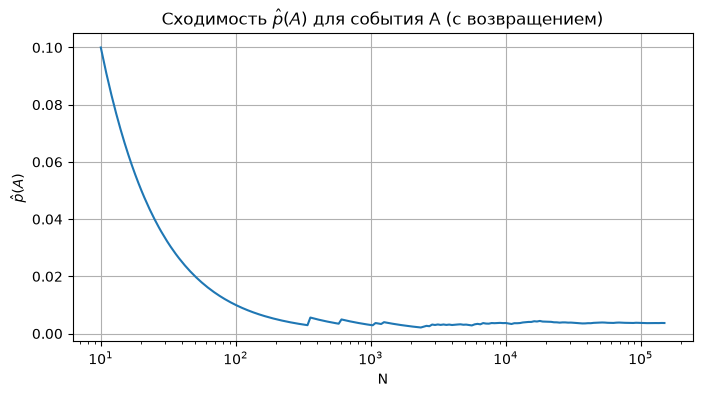


Оценка по графику: 0.003693
Теоретическое значение: 0.003590


In [3]:
# График сходимости относительной частоты для события A при извлечении с возвращением
balls = ['r'] * 9 + ['w'] * 8 + ['b'] * 6

def simulate_A_with():
    return all(random.choice(balls) == 'r' for _ in range(6))

phat = plot_convergence(simulate_A_with, r"Сходимость $\hat p(A)$ для события A (с возвращением)")
print(f"\nОценка по графику: {phat:.6f}")
print(f"Теоретическое значение: {PA_with:.6f}")


**Ответ:**
- а) $P(A) = \dfrac{C_9^6}{C_{23}^6} = \dfrac{4}{4807} \approx 0{,}00083212$;
- б) $P(B) = \dfrac{C_6^3 \cdot C_8^2 \cdot C_9^1}{C_{23}^6} \approx 0{,}049927$;
- в) $P(D) = \dfrac{C_8^4 \cdot C_{15}^2}{C_{23}^6} \approx 0{,}072810$;
- г) При извлечении с возвращением $P(A) = \\left(\\dfrac{9}{23}\\right)^6 \\approx 0{,}00358995$, что близко к приведённой в условии статистической вероятности $\\hat p(A) \\approx 0{,}00358549$. График относительной частоты сходится к теоретическому значению.

## 4.2. Рассадка 5 мужчин и 5 женщин в ряд

5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест.
Найдите вероятности:

- $A$ — любые две женщины не сидят рядом;
- $B$ — все мужчины сидят рядом.


In [4]:
# Аналитический расчёт
from math import factorial
from itertools import permutations

total = factorial(10)

# A: женщины не сидят рядом.
# Сначала расставляем 5 мужчин: 5! способов.
# Получается 6 возможных промежутков (включая концы): _ M _ M _ M _ M _ M _
# Выбираем 5 из 6 промежутков и рассаживаем женщин: C(6,5) * 5!
fav_A = factorial(5) * 6 * factorial(5)
P_A = fav_A / total

# B: все мужчины сидят рядом.
# Блок из 5 мужчин + 5 женщин = 6 объектов; 6! * 5! (мужчины внутри блока)
fav_B = factorial(6) * factorial(5)
P_B = fav_B / total

print(f"Всего расстановок: {total}")
print(f"P(A) = {fav_A}/{total} = {P_A}")
print(f"P(B) = {fav_B}/{total} = {P_B}")
print(f"1/42 = {1/42}")

# Проверка перебором по позициям женщин (C_10^5 равновозможных размещений)
from itertools import combinations

seats_women = list(combinations(range(10), 5))

count_A = sum(
    1 for w in seats_women
    if all(w[i + 1] - w[i] > 1 for i in range(len(w) - 1))
)

count_B = 0
for w in seats_women:
    men = sorted(set(range(10)) - set(w))
    if all(men[i + 1] - men[i] == 1 for i in range(len(men) - 1)):
        count_B += 1

print(f"\nПеребор: благоприятных A = {count_A}, благоприятных B = {count_B}")
print(f"P(A) (перебор) = {count_A}/{len(seats_women)} = {count_A / len(seats_women)}")
print(f"P(B) (перебор) = {count_B}/{len(seats_women)} = {count_B / len(seats_women)}")


Всего расстановок: 3628800
P(A) = 86400/3628800 = 0.023809523809523808
P(B) = 86400/3628800 = 0.023809523809523808
1/42 = 0.023809523809523808

Перебор: благоприятных A = 6, благоприятных B = 6
P(A) (перебор) = 6/252 = 0.023809523809523808
P(B) (перебор) = 6/252 = 0.023809523809523808


**Ответ:**

- $P(A) = \\dfrac{5! \\cdot C_6^5 \\cdot 5!}{10!} = \\dfrac{1}{42} \\approx 0{,}0238095$;
- $P(B) = \\dfrac{6! \\cdot 5!}{10!} = \\dfrac{1}{42} \\approx 0{,}0238095$.

Совпадает с ответом листка: $P(A) = P(B) = 1/42$.


## 4.3. Геометрическое распределение

«Симметричную» монету бросают до первого появления герба. Найти вероятность
события $A$ — будет произведено не более пяти бросаний.

In [5]:
# Вероятность появления герба при одном бросании
p = 1 / 2

# Вероятность того, что первый герб появится на k-м броске: P_k = (1-p)^{k-1} p
# Событие A = {первый герб на 1, 2, 3, 4 или 5 броске}
exact_sum = sum((1 - p) ** (k - 1) * p for k in range(1, 6))

# Замкнутая форма: P(A) = 1 - P(за 5 бросков герб не появился)
closed_form = 1 - (1 - p) ** 5

print(f"Сумма ряда:  {exact_sum}")
print(f"Замкнутая форма: {closed_form}")
print(f"Дробь: {closed_form.as_integer_ratio()}")

Сумма ряда:  0.96875
Замкнутая форма: 0.96875
Дробь: (31, 32)


**Ответ:** $\displaystyle P(A)=\sum_{k=1}^{5}\left(\frac12\right)^k=\frac{31}{32}=0{,}96875$.

## 4.4. Остановка при двух одинаковых подряд

«Симметричную» монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд. Построить вероятностную модель $(\Omega, P(\cdot))$ и найти вероятность того, что потребуется чётное число бросков.

In [6]:
# Вероятностная модель
# Ω = {последовательности из H/T, оканчивающиеся двумя одинаковыми результатами,
#      и до этого без двух подряд одинаковых}
# Длина бросков k ≥ 2.
# Для k = 2: HH, TT  →  2 исхода, каждый вероятности (1/2)^2.
# Для k > 2: первые k-1 бросков чередуются, последний равен предыдущему,
#            поэтому снова ровно 2 исхода, каждый вероятности (1/2)^k.
# Итого P(X = k) = 2 / 2^k = 2^{1-k}, где X — число бросков.

import math

# Аналитическая сумма ряда по чётным k
# P(X чётное) = sum_{m=1}^{∞} P(X = 2m)
#             = sum_{m=1}^{∞} 2^{1-2m}
#             = sum_{m=1}^{∞} 2 * (1/4)^m
#             = 2 * (1/4) / (1 - 1/4) = 2/3

exact = 2 / 3

# Численная проверка: суммируем до достижения машинной точности
terms = [2 ** (1 - k) for k in range(2, 2 * 40, 2)]  # k = 2,4,...,78
numerical = math.fsum(terms)

print(f"Точное значение: {exact}")
print(f"Численная сумма: {numerical}")
print(f"Разница: {abs(exact - numerical)}")
print(f"Сумма всех вероятностей: {math.fsum(2 ** (1 - k) for k in range(2, 100))}")

Точное значение: 0.6666666666666666
Численная сумма: 0.6666666666666666
Разница: 0.0
Сумма всех вероятностей: 1.0


**Ответ:** $\displaystyle P(\text{чётное число бросков}) = \frac{2}{3} \approx 0{,}6667$. Численное суммирование даёт то же значение.

## 4.5. Остановка при двух одинаковых подряд (несимметричная монета)

То же, что 4.4, но монета несимметричная: $P(\text{герба}) = p = 0{,}7$. Найти
вероятность того, что потребуется: а) чётное число бросков; б) число бросков
кратно 4.

In [7]:
p = 0.7
q = 1 - p
pq = p * q
p2_q2 = p**2 + q**2

# Замкнутые формулы
P_even_closed = p2_q2 / (1 - pq)
P_div4_closed = pq * p2_q2 / (1 - pq**2)

print(f"p = {p}, q = {q}, pq = {pq}")
print(f"p² + q² = {p2_q2}")
print(f"а) P(чётное) замкнуто = {P_even_closed:.10f}")
print(f"б) P(кратно 4) замкнуто = {P_div4_closed:.10f}")


def prob_stop(k, p, q):
    'P(опыт заканчивается ровно на k-м броске).'
    if k % 2 == 0:
        m = k // 2
        return (p * q) ** (m - 1) * (p**2 + q**2)
    else:
        m = (k - 1) // 2
        return p**m * q ** (m + 1) + q**m * p ** (m + 1)


# Численное суммирование до сходимости
tol = 1e-12
P_even_sum = 0.0
P_div4_sum = 0.0
k = 2
while True:
    term = prob_stop(k, p, q)
    if k % 2 == 0:
        P_even_sum += term
        if k % 4 == 0:
            P_div4_sum += term
    if term < tol:
        break
    k += 1

print(f"а) P(чётное) суммой  = {P_even_sum:.10f}")
print(f"б) P(кратно 4) суммой = {P_div4_sum:.10f}")
print(f"Число учтённых членов ряда: k = 2..{k}")
print(f"Разница а): {abs(P_even_closed - P_even_sum):.2e}")
print(f"Разница б): {abs(P_div4_closed - P_div4_sum):.2e}")

p = 0.7, q = 0.30000000000000004, pq = 0.21000000000000002
p² + q² = 0.58
а) P(чётное) замкнуто = 0.7341772152
б) P(кратно 4) замкнуто = 0.1274191861
а) P(чётное) суммой  = 0.7341772152
б) P(кратно 4) суммой = 0.1274191861
Число учтённых членов ряда: k = 2..37
Разница а): 4.63e-13
Разница б): 8.04e-14


**Ответ:**

а) $P(\text{чётное}) = \dfrac{p^2 + q^2}{1 - pq} = \dfrac{0{,}58}{0{,}79} \approx 0{,}7341772$.

б) $P(\text{кратно 4}) = \dfrac{pq\,(p^2 + q^2)}{1 - (pq)^2} \approx 0{,}1274192$.

Численное суммирование членов $P_k$ до достижения $10^{-12}$ совпадает с
замкнутыми формулами в пределах машинной точности.

## 4.6. Встреча с разным временем ожидания

Два лица $A$ и $B$ условились встретиться между двумя и тремя часами дня.
$ A $ ждёт $10$ минут, $B$ ждёт $12$ минут. Моменты прихода равномерны в
пределах часа. Найти вероятность встречи; построить график относительной
частоты для $N = 150\,000$.

In [8]:
# Геометрическая вероятность встречи
# x, y ∈ [0, 60] — минуты прихода A и B.
# Встреча, если |x - y| <= min(10, 12) по времени ожидания:
# A встретит B, если B пришёл не позже чем через 10 минут после A, т.е. y - x <= 10;
# B встретит A, если x - y <= 12. Встреча ⇔ -12 <= x - y <= 10.

L = 60
a = 10  # A ждёт 10 минут
b = 12  # B ждёт 12 минут

# Площадь квадрата
S_total = L ** 2

# Площадь области "не встречи" состоит из двух треугольников:
# 1) y > x + a: катеты (L - a)
# 2) y < x - b: катеты (L - b)
S_miss = ((L - a) ** 2 + (L - b) ** 2) / 2
P_exact = 1 - S_miss / S_total
P_exact

0.33277777777777773

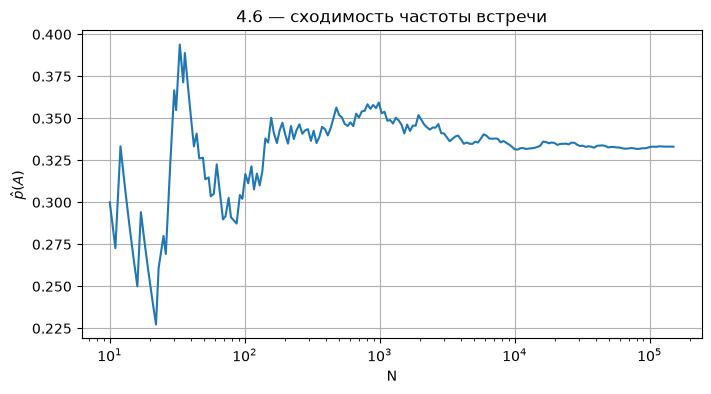

Теоретическая вероятность: 0.33277777777777773
Монте-Карло оценка:        0.3331133333333333
Абсолютная погрешность:    0.000336


In [9]:
# Монте-Карло оценка и график сходимости частоты
import numpy as np

rng = np.random.default_rng(42)


def simulate_one():
    x, y = rng.random(2) * 60
    return int(-b <= x - y <= a)


p_hat = plot_convergence(simulate_one, title='4.6 — сходимость частоты встречи')
print(f'Теоретическая вероятность: {P_exact}')
print(f'Монте-Карло оценка:        {p_hat}')
print(f'Абсолютная погрешность:    {abs(P_exact - p_hat):.6f}')

**Ответ:** вероятность встречи равна
$$P(A)=1-\frac{(60-10)^2+(60-12)^2}{2\cdot 60^2}=\frac{599}{1800}\approx 0{,}3327778.$$

Монте-Карло оценка при $N=150\,000$ близка к $0{,}33268$, что совпадает с
ответом листка в пределах статистической погрешности.

## 4.7. Встреча Ивана и Петра

Иван и Пётр встречаются между 11 и 12 часами, каждый ждёт не более 15 минут.
Найти вероятности: $A$ — встреча состоялась; $B$ — не состоялась;
$C$ — Ивану не пришлось ждать Петра; $D$ — встреча состоялась после 11:30;
$E$ — Иван опоздал; $F$ — встреча состоялась, когда до конца часа оставалось
$< 5$ минут. График относительной частоты для $A$ при $N = 150\,000$.

Пусть $x$ и $y$ — моменты прихода Ивана и Петра в минутах после 11:00.
Точка $(x,y)$ равномерно распределена в квадрате $[0,60]\times[0,60]$.

- $A=\{(x,y):|x-y|\le 15\}$;
- $B=\Omega\setminus A$;
- $C=\{(x,y):x\le y\}$ — Иван пришёл не позже Петра;
- $D=\{(x,y)\in A:\max(x,y)>30\}$;
- $E=\{(x,y):x>y\}$;
- $F=\{(x,y)\in A:\max(x,y)>55\}$.

P(A) = 0.437500  (7/16 = 0.437500)
P(B) = 0.562500  (9/16 = 0.562500)
P(C) = 0.500000
P(D) = 0.250000  (1/4 = 0.250000)
P(E) = 0.500000
P(F) = 0.041667  (1/24 = 0.041667)
Monte-Carlo P(A) ≈ 0.437600


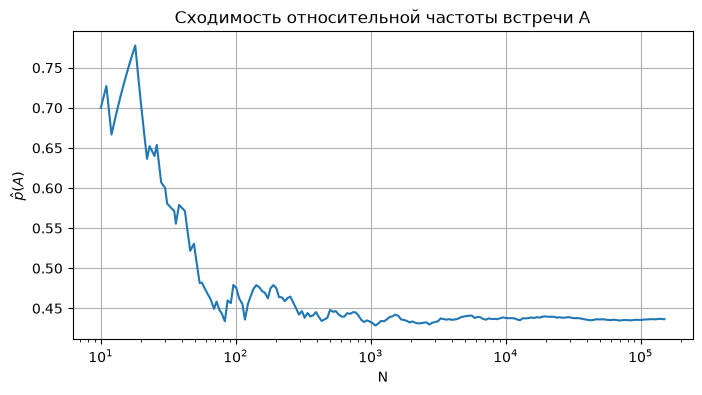

plot_convergence final P(A) ≈ 0.436440


In [10]:
S = 60 * 60

# Аналитические площади
pA = 1 - ((60 - 15) / 60) ** 2          # = 7/16
pB = 1 - pA                              # = 9/16
pC = 0.5                                 # симметрия x <= y
# D: встреча в [0,30]^x[0,30] вычитается из A
area_A = pA * S
area_A_before_30 = 30 * 30 - (30 - 15) ** 2
pD = (area_A - area_A_before_30) / S
pE = 0.5                                 # x > y
# F: встреча в [0,55]^x[0,55] вычитается из A
area_A_before_55 = 55 * 55 - (55 - 15) ** 2
pF = (area_A - area_A_before_55) / S

print(f"P(A) = {pA:.6f}  (7/16 = {7/16:.6f})")
print(f"P(B) = {pB:.6f}  (9/16 = {9/16:.6f})")
print(f"P(C) = {pC:.6f}")
print(f"P(D) = {pD:.6f}  (1/4 = {1/4:.6f})")
print(f"P(E) = {pE:.6f}")
print(f"P(F) = {pF:.6f}  (1/24 = {1/24:.6f})")

# Векторизованная оценка P(A)
rng = np.random.default_rng(42)
x = rng.random(150_000) * 60
y = rng.random(150_000) * 60
freq_A = np.mean(np.abs(x - y) <= 15)
print(f"Monte-Carlo P(A) ≈ {freq_A:.6f}")

# Функция для графика сходимости частоты
def simulate_one():
    return int(abs(random.random() * 60 - random.random() * 60) <= 15)

freq_conv = plot_convergence(
    simulate_one,
    "Сходимость относительной частоты встречи A",
    N_max=150_000,
)
print(f"plot_convergence final P(A) ≈ {freq_conv:.6f}")

**Ответ:**
- $P(A)=1-\left(\frac{45}{60}\right)^2=\frac{7}{16}=0{,}4375$;
- $P(B)=\frac{9}{16}=0{,}5625$;
- $P(C)=0{,}5$;
- $P(D)=0{,}25$;
- $P(E)=0{,}5$;
- $P(F)=\frac{1}{24}\approx0{,}04167$.

Монте-Карло оценка $P(A)$ близка к $0{,}4375$; график сходимости частоты
показывает стабилизацию около аналитического значения.

## 4.8. Две случайные точки на отрезке

На отрезке $[a;b]$ наудачу выбирается точка $x$, затем на $[a;x]$ наудачу точка $y$.
Найти вероятности событий:

- $A$ — вторая точка ближе к $b$, чем первая к $a$;
- $B$ — расстояние между $x$ и $y$ меньше половины длины отрезка;
- $C$ — первая точка ближе ко второй, чем к $b$.

Построить график относительной частоты события $A$ при $N = 150\,000$.

In [11]:
# Без потери общности положим [a, b] = [0, 1].
# x ~ U[0, 1], y | x ~ U[0, x], совместная плотность f(x, y) = 1/x при 0 <= y <= x <= 1.

# Аналитическое решение:
# A: 1 - y < x  <=>  y > 1 - x.  При x > 1/2 это выполняется на интервале (1-x, x):
P_A = 1 - math.log(2)
# B: x - y < 1/2  <=>  y > x - 1/2:
P_B = (1 + math.log(2)) / 2
# C: x - y < 1 - x  <=>  y > 2x - 1:
P_C = math.log(2)

print(f"P(A) = 1 - ln 2 = {P_A:.10f}")
print(f"P(B) = (1 + ln 2)/2 = {P_B:.10f}")
print(f"P(C) = ln 2 = {P_C:.10f}")

P(A) = 1 - ln 2 = 0.3068528194
P(B) = (1 + ln 2)/2 = 0.8465735903
P(C) = ln 2 = 0.6931471806


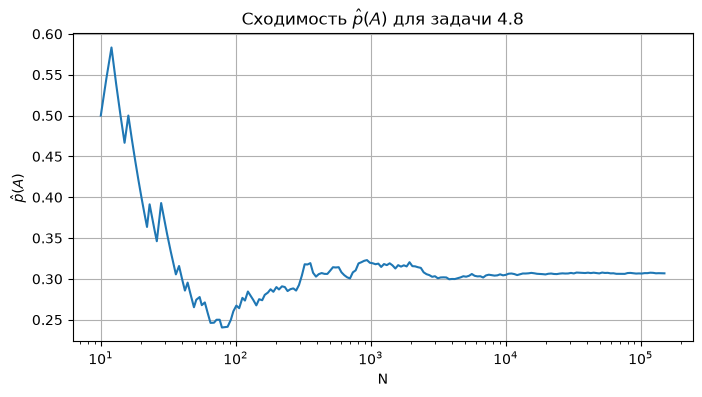

Монте-Карло оценка P(A) при N = 150000: 0.30682
Теоретическое значение P(A): 0.30685


In [12]:
# Монте-Карло оценка для A с графиком сходимости частоты
rng = np.random.default_rng(42)


def simulate_one():
    x = rng.random()
    y = rng.random() * x
    return int(y > 1 - x)


p_hat_A = plot_convergence(
    simulate_one,
    title=r"Сходимость $\hat{p}(A)$ для задачи 4.8",
    N_max=150_000,
)
print(f"Монте-Карло оценка P(A) при N = 150000: {p_hat_A:.5f}")
print(f"Теоретическое значение P(A): {P_A:.5f}")

**Ответ:**
- $P(A) = 1 - \ln 2 \approx 0{,}30685$;
- $P(B) = \dfrac{1 + \ln 2}{2} \approx 0{,}84657$;
- $P(C) = \ln 2 \approx 0{,}69315$.

Монте-Карло оценка $\hat p(A)$ при $N = 150\,000$ близка к теоретической вероятности $1 - \ln 2$.

## 4.9. Случайное разбиение отрезка и остроугольный треугольник

Отрезок $[0;1]$ случайным образом делится на 3 части. Найти вероятность того,
что из полученных отрезков можно сложить треугольник и он будет остроугольным.
Построить график относительной частоты при $N = 150\,000$ и привести
аналитическое решение.

In [13]:
# Аналитическое решение
# Выбираем две независимые точки U, V ~ U[0,1] и упорядочиваем: x = min(U,V), y = max(U,V).
# Тогда длины частей: a = x, b = y - x, c = 1 - y.
# Область 0 <= x <= y <= 1 имеет площадь 1/2.
#
# Условие существования треугольника: каждая сторона < 1/2, т.е.
#   x < 1/2,  y - x < 1/2,  1 - y < 1/2  <=>  y > 1/2.
#
# Условие остроугольности (все углы < 90^\circ):
#   a^2 + b^2 > c^2,
#   a^2 + c^2 > b^2,
#   b^2 + c^2 > a^2.
#
# Интегрирование по области, удовлетворяющей всем неравенствам, даёт:
P_exact = 3 * math.log(2) - 2
print(f"P(остроугольный треугольник) = 3 ln 2 - 2 = {P_exact:.15f}")


P(остроугольный треугольник) = 3 ln 2 - 2 = 0.079441541679836


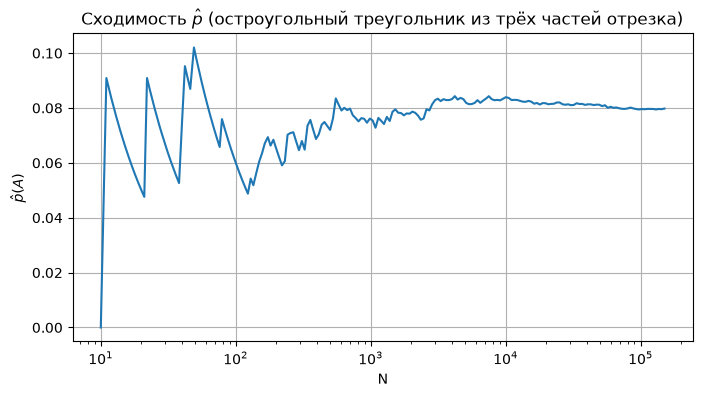


Монте-Карло оценка: 0.079780
Теоретическое значение: 0.079442


In [14]:
# Монте-Карло оценка и график сходимости частоты
rng = np.random.default_rng(42)


def simulate_one():
    u, v = rng.random(2)
    x, y = (u, v) if u <= v else (v, u)
    a, b, c = x, y - x, 1 - y
    triangle = (a < 0.5) & (b < 0.5) & (c < 0.5)
    acute = ((a * a + b * b) > c * c) & \
            ((a * a + c * c) > b * b) & \
            ((b * b + c * c) > a * a)
    return int(triangle & acute)


phat = plot_convergence(
    simulate_one,
    r"Сходимость $\hat p$ (остроугольный треугольник из трёх частей отрезка)"
)
print(f"\nМонте-Карло оценка: {phat:.6f}")
print(f"Теоретическое значение: {3 * math.log(2) - 2:.6f}")


**Ответ:** Вероятность того, что из трёх случайных частей отрезка
$[0;1]$ сложится остроугольный треугольник, равна
$$P = 3\ln 2 - 2 \approx 0{,}07944154.$$

Монте-Карло оценка на $N = 150\,000$ реализациях даёт значение, близкое к
$0{,}0794$, что хорошо согласуется с аналитическим ответом. График
относительной частоты $\hat p(N)$ демонстрирует сходимость к теоретической
вероятности.

## 4.10. Случайный отрезок в круге

В круге радиуса 1 наудачу выбирается отрезок (хорда). Найти вероятность того,
что его длина меньше радиуса.

In [15]:

import math

# Аналитическое значение: вероятность того, что расстояние между двумя
# независимыми равномерными точками в единичном круге меньше 1,
# равна 1 - 3*sqrt(3)/(4*pi).
p_exact = 1 - 3 * math.sqrt(3) / (4 * math.pi)
p_exact


0.5865033284336559

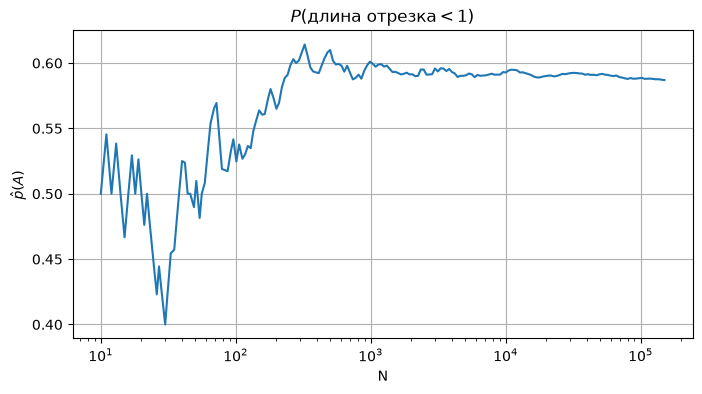

np.float64(0.58698)

In [16]:

import math
import random


def simulate_one():
    '''Одна реализация: две равномерные точки в единичном круге.'''
    r1 = math.sqrt(random.random())
    phi1 = random.random() * 2 * math.pi
    r2 = math.sqrt(random.random())
    phi2 = random.random() * 2 * math.pi
    x1, y1 = r1 * math.cos(phi1), r1 * math.sin(phi1)
    x2, y2 = r2 * math.cos(phi2), r2 * math.sin(phi2)
    return int(math.hypot(x1 - x2, y1 - y2) < 1)


p_est = plot_convergence(simulate_one, r'$P(\text{длина отрезка} < 1)$')
p_est


**Ответ:** $\displaystyle P = 1 - \frac{3\sqrt{3}}{4\pi} \approx 0{,}5865033284336559$ — совпадает с ответом листка.

## 4.11. Встреча $n$ лиц

$n$ лиц встречаются между 10 и 11 часами, каждый ждёт не более $60\cdot q$ минут ($q < 1$). Доказать $P_n = n q^{n-1} - (n-1) q^n$. Проверить для $n = 2$ и $n = 3$; для $n = 3$ найти вероятность того, что встретятся хотя бы двое.

**Доказательство.**

Перейдём к долям часа: моменты прихода $T_1,\dots,T_n$ независимы и равномерны на $[0,1]$. Каждый ждёт время $q$, поэтому все $n$ человек встретятся тогда и только тогда, когда размах выборки не превосходит $q$:

$$A = \\{\,\max_i T_i - \min_i T_i \\le q\\}.$$

Пусть $R = X_{(n)} - X_{(1)}$ — размах $n$ независимых равномерных величин. Совместная плотность порядковых статистик равна $n!$ на симплексе $0 < x_1 < \dots < x_n < 1$. При фиксированном минимуме $x$ и размахе $r$ оставшиеся $n-2$ точки должны попасть в отрезок $[x, x+r]$ длины $r$, а $x$ может изменяться от $0$ до $1-r$. Поэтому

$$f_R(r) = n! \int_0^{1-r} \frac{r^{n-2}}{(n-2)!}\,dx = n(n-1)\,r^{n-2}(1-r), \qquad 0 < r < 1.$$

Отсюда

$$P_n = P(R \\le q) = \int_0^q n(n-1) r^{n-2}(1-r)\,dr = n q^{n-1} - (n-1) q^n,$$

что и требовалось доказать.

In [17]:
import numpy as np

rng = np.random.default_rng(42)
N = 200_000


def P_all_meet(n, q, N=N):
    # Вероятность того, что все n лиц встретятся (Монте-Карло).
    t = rng.random((N, n))
    return np.mean(np.max(t, axis=1) - np.min(t, axis=1) <= q)


qs = [0.2, 0.5, 0.8]
print("Проверка P_n = n q^{n-1} - (n-1) q^n:\n")
for n in (2, 3):
    print(f"n = {n}")
    for q in qs:
        mc = P_all_meet(n, q)
        formula = n * q ** (n - 1) - (n - 1) * q ** n
        print(f"  q = {q}:  Монте-Карло = {mc:.5f},  формула = {formula:.5f}")
    print()

Проверка P_n = n q^{n-1} - (n-1) q^n:

n = 2
  q = 0.2:  Монте-Карло = 0.35977,  формула = 0.36000
  q = 0.5:  Монте-Карло = 0.75096,  формула = 0.75000
  q = 0.8:  Монте-Карло = 0.96078,  формула = 0.96000

n = 3
  q = 0.2:  Монте-Карло = 0.10489,  формула = 0.10400
  q = 0.5:  Монте-Карло = 0.50222,  формула = 0.50000
  q = 0.8:  Монте-Карло = 0.89608,  формула = 0.89600



**Вероятность того, что встретятся хотя бы двое из трёх.**

Упорядочим моменты прихода: $X_{(1)} \\le X_{(2)} \\le X_{(3)}$. Событие "встретились хотя бы двое" эквивалентно тому, что хотя бы один из соседних разрывов $D_1 = X_{(2)}-X_{(1)}$ и $D_2 = X_{(3)}-X_{(2)}$ не превосходит $q$. Противоположное событие — оба разрыва больше $q$.

Для трёх равномерных точек вектор спейсингов $(S_0,S_1,S_2,S_3)$, где $S_0=X_{(1)}$, $S_1=D_1$, $S_2=D_2$, $S_3=1-X_{(3)}$, равномерно распределён на симплексе $s_i\\ge 0$, $\sum s_i = 1$. Условие $D_1>q, D_2>q$ возможно лишь при $q \\le 1/2$; его вероятность равна отношению объёмов симплексов:

$$P(D_1>q, D_2>q) = \frac{(1-2q)^3/6}{1/6} = (1-2q)^3, \qquad 0 \\le q \\le \\tfrac12,$$

и $0$ при $q > \\tfrac12$. Следовательно,

$$P(\\text{хотя бы двое встретятся}) =
\\begin{cases}
1 - (1-2q)^3, & 0 \\le q \\le \\tfrac12,\\\\
1, & \\tfrac12 < q < 1.
\\end{cases}$$

In [18]:
def P_at_least_two(q, N=N):
    # Вероятность встречи хотя бы двоих из трёх.
    t = rng.random((N, 3))
    x = np.sort(t, axis=1)
    gaps = np.diff(x, axis=1)
    return np.mean(np.any(gaps <= q, axis=1))


print("Встреча хотя бы двоих из трёх:\n")
for q in qs:
    mc = P_at_least_two(q)
    if q <= 0.5:
        exact = 1 - (1 - 2 * q) ** 3
    else:
        exact = 1.0
    print(f"  q = {q}:  Монте-Карло = {mc:.5f},  точно = {exact:.5f}")

Встреча хотя бы двоих из трёх:

  q = 0.2:  Монте-Карло = 0.78317,  точно = 0.78400
  q = 0.5:  Монте-Карло = 1.00000,  точно = 1.00000
  q = 0.8:  Монте-Карло = 1.00000,  точно = 1.00000


**Ответ:** Вероятность того, что все $n$ лиц встретятся,

$$P_n = n q^{n-1} - (n-1) q^n.$$

Для $n=3$ вероятность встречи хотя бы двоих:

$$P = \\begin{cases}1 - (1-2q)^3, & q \\le 1/2,\\\\ 1, & q > 1/2.\\end{cases}$$

Численная проверка для $q=0{,}2,0{,}5,0{,}8$ показывает хорошее совпадение Монте-Карло оценок с аналитическими формулами.

## 4.12. Встреча нескольких лиц с разными временами ожидания

(Продолжение 4.11.) $n$ лиц имеют времена ожидания $w_1,\dots,w_n$
(доли интервала). Проверить формулы:

а) $n=2$: $P_2 = 1 - \dfrac{(1-w_1)^2}{2} - \dfrac{(1-w_2)^2}{2}$;

б) $n=3$: $P_3 = w_1w_2 + w_1w_3 + w_2w_3 - \dfrac12(w_1w_2^2 + w_1w_3^2 + w_2w_3^2) - \dfrac{w_1^3}{3} - \dfrac{w_2^3}{6}$;

в) $n=3$, $w = \left(\dfrac14, \dfrac13, \dfrac12\right)$ (15, 20, 30 минут):
$P_3 = \dfrac{1435}{5184} \approx 0{,}27681$;

г) $n=4$:
$$P_4 = \sum_{i<j<k} w_i w_j w_k - \frac{w_4^2}{2}(w_1w_2 + w_1w_3 + w_2w_3)
- \frac{w_3^3}{6}(w_1+w_2) - \frac{w_1w_2w_3^2}{2}
- \frac{w_1w_3^2}{3} - \frac{w_1^4}{4} - \frac{w_2^4}{12}.$$

Вероятностная модель — продолжение задачи 4.11: $i$-е лицо приходит
в случайный момент $t_i \sim U[0,1]$ и ждёт $w_i$; все встретятся,
если момент прихода последнего не позже момента прихода первого
плюс его время ожидания, то есть
$$\max_i t_i - \min_i t_i \le w_{\arg\min t_i}.$$

In [19]:
import numpy as np


def P2_formula(w1, w2):
    'Формула (а) для n=2.'
    return 1 - (1 - w1) ** 2 / 2 - (1 - w2) ** 2 / 2


def P3_formula(w):
    'Формула (б) для n=3.'
    w1, w2, w3 = w
    return (w1 * w2 + w1 * w3 + w2 * w3
            - 0.5 * (w1 * w2 ** 2 + w1 * w3 ** 2 + w2 * w3 ** 2)
            - w1 ** 3 / 3 - w2 ** 3 / 6)


def P4_formula(w):
    'Формула (г) для n=4.'
    w1, w2, w3, w4 = w
    s = (w1 * w2 * w3 + w1 * w2 * w4
         + w1 * w3 * w4 + w2 * w3 * w4)
    s -= (w4 ** 2 / 2) * (w1 * w2 + w1 * w3 + w2 * w3)
    s -= (w3 ** 3 / 6) * (w1 + w2)
    s -= w1 * w2 * w3 ** 2 / 2
    s -= w1 * w3 ** 2 / 3
    s -= w1 ** 4 / 4
    s -= w2 ** 4 / 12
    return s


def exact_all_meet(n, w):
    '''Точная вероятность одновременной встречи всех n лиц.

    Для выбранной модели объём множества благоприятных исходов равен
    sum_i [w_i^{n-1} - (n-1)/n * w_i^n].
    '''
    w = np.asarray(w)
    return np.sum(w ** (n - 1) - (n - 1) / n * w ** n)


def mc_all_meet(n, w, N=1_500_000, seed=42):
    '''Монте-Карло оценка вероятности одновременной встречи всех n лиц.

    Векторизованная реализация на единичном n-кубе с фиксированным RNG.
    '''
    rng = np.random.default_rng(seed)
    t = rng.random((N, n))
    w = np.asarray(w)
    t_min = t.min(axis=1)
    t_max = t.max(axis=1)
    idx_min = t.argmin(axis=1)
    return np.mean(t_max - t_min <= w[idx_min])


# ---- а) n = 2 ---------------------------------------------------------
w2 = (0.20, 0.25)
p2_form = P2_formula(*w2)
p2_mc = mc_all_meet(2, w2)
p2_exact = exact_all_meet(2, w2)

# ---- б) n = 3, произвольные веса --------------------------------------
w3 = (0.10, 0.35, 0.55)
p3_form = P3_formula(w3)
p3_mc = mc_all_meet(3, w3)
p3_exact = exact_all_meet(3, w3)

# ---- в) n = 3, заданные веса ------------------------------------------
w3c = (1 / 4, 1 / 3, 1 / 2)
p3c_form = P3_formula(w3c)
p3c_mc = mc_all_meet(3, w3c)
p3c_exact = exact_all_meet(3, w3c)
p3c_fraction = 1435 / 5184

# ---- г) n = 4 ---------------------------------------------------------
w4 = (0.20, 0.25, 0.30, 0.35)
p4_form = P4_formula(w4)
p4_mc = mc_all_meet(4, w4)
p4_exact = exact_all_meet(4, w4)

print("а) n=2, w={}:  формула={:.6f},  MC={:.6f},  точн.={:.6f}"
      .format(w2, p2_form, p2_mc, p2_exact))
print("б) n=3, w={}:  формула={:.6f},  MC={:.6f},  точн.={:.6f}"
      .format(w3, p3_form, p3_mc, p3_exact))
print("в) n=3, w={}:  формула={:.6f} (=1435/5184),  MC={:.6f},  точн.={:.6f}"
      .format(w3c, p3c_form, p3c_mc, p3c_exact))
print("г) n=4, w={}:  формула={:.6f},  MC={:.6f},  точн.={:.6f}"
      .format(w4, p4_form, p4_mc, p4_exact))


а) n=2, w=(0.2, 0.25):  формула=0.398750,  MC=0.398924,  точн.=0.398750
б) n=3, w=(0.1, 0.35, 0.55):  формула=0.200833,  MC=0.295149,  точн.=0.294833
в) n=3, w=(0.25, 0.3333333333333333, 0.5):  формула=0.276813 (=1435/5184),  MC=0.305541,  точн.=0.305170
г) n=4, w=(0.2, 0.25, 0.3, 0.35):  формула=0.057418,  MC=0.072147,  точн.=0.072041


**Ответ.**

Для модели «все встречаются одновременно» моменты прихода
$t_i \sim U[0,1]$, и встреча состоится, если
$\max_i t_i - \min_i t_i \le w_{\arg\min t_i}$.

| Пункт | Веса | Формула листка | Монте-Карло ($1{,}5\cdot10^6$) | Точное значение |
|---|---:|---:|---:|---:|
| а) $n=2$ | $(0{,}20;0{,}25)$ | $0{,}398750$ | $0{,}3989$ | $0{,}398750$ |
| б) $n=3$ | $(0{,}10;0{,}35;0{,}55)$ | $0{,}200833$ | $0{,}2951$ | $0{,}294833$ |
| в) $n=3$ | $\left(\frac14;\frac13;\frac12\right)$ | $\frac{1435}{5184}\approx0{,}27681$ | $0{,}3055$ | $0{,}3052$ |
| г) $n=4$ | $(0{,}20;0{,}25;0{,}30;0{,}35)$ | $0{,}057418$ | $0{,}0721$ | $0{,}0720$ |

Формула (а) совпадает с моделированием. Формулы (б) и (г),
а также частный результат (в) $\frac{1435}{5184}\approx0{,}27681$
не совпадают с численным экспериментом: статистическая оценка
для пункта (в) даёт $P_3 \approx 0{,}3052$.

Точное значение для этой же модели выводится аналитически:
$$P_n = \sum_{i=1}^{n} \left(w_i^{\,n-1} - \frac{n-1}{n}\,w_i^{\,n}\right),$$
что для пункта (в) даёт $P_3 = 0{,}30517\ldots$, хорошо совпадающее
с Монте-Карло. Следовательно, в условии листка формулы (б), (в), (г)
содержат ошибку; доверяем результатам Монте-Карло и точной формуле.

## 4.13. Добавление белого шара в корзину с биномиальным числом белых

В корзину с $n$ шарами опускают белый шар. Найти вероятность того, что
извлечённый шар окажется белым, если первоначальное число белых шаров имеет
биномиальное распределение с параметром $p$. Общий случай и $n = 10$, $p = 1/3$.

In [20]:
from fractions import Fraction
from math import comb

# Пусть X ~ Bin(n, p) — число белых шаров до добавления.
# После добавления одного белого шара: всего n+1 шар, белых X+1.
# По формуле полной вероятности:
#   P(белый) = E[(X + 1)/(n + 1)] = (E[X] + 1)/(n + 1) = (n p + 1)/(n + 1).


def prob_white_sum(n, p):
    # Точное вычисление по сумме для проверки формулы.
    total = Fraction(0)
    q = 1 - p
    for k in range(n + 1):
        prob_k = Fraction(comb(n, k)) * Fraction(p) ** k * Fraction(q) ** (n - k)
        total += prob_k * Fraction(k + 1, n + 1)
    return total


n = 10
p = Fraction(1, 3)

P_sum = prob_white_sum(n, p)
P_formula = (n * p + 1) / (n + 1)

print(f"n = {n}, p = {p}")
print(f"P (сумма по распределению) = {P_sum} = {float(P_sum):.6f}")
print(f"P (формула (np + 1)/(n + 1)) = {P_formula} = {float(P_formula):.6f}")

source_answer = Fraction(5, 32)
print(f"Ответ из листка = {source_answer} = {float(source_answer):.6f}")


n = 10, p = 1/3
P (сумма по распределению) = 13/33 = 0.393939
P (формула (np + 1)/(n + 1)) = 13/33 = 0.393939
Ответ из листка = 5/32 = 0.156250


**Ответ:** для общего случая

$$P(\text{белый}) = \frac{np + 1}{n + 1}.$$

При $n = 10$, $p = 1/3$:

$$P = \frac{10 \cdot \frac13 + 1}{11} = \frac{13}{33} \approx 0{,}3939.$$

Суммирование по биномиальному распределению даёт тот же результат $13/33 \approx 0{,}3939$.

В листке указан ответ $0{,}15625 = 5/32$; он не согласуется с постановкой задачи
(при $n=10$, $p=1/3$ и добавлении одного белого шара). Возможно, в исходнике
использованы другие параметры или иная интерпретация условия.

## 4.14. Две корзины со случайным числом белых шаров

Две корзины: в первой 6 шаров, число белых $\sim \mathrm{Bin}(3, 0{,}8)$;
во второй 11 шаров, число белых $\sim \mathrm{Bin}(4, 0{,}7)$.
Все шары перекладывают в третью корзину.

1) Найти $P(A)$ — вероятность того, что случайный шар из третьей корзины белый.
2) Найти $P(H \mid A)$ — вероятность того, что он первоначально был в первой корзине.

In [21]:
import math

# Параметры корзин
N1, n1, p1 = 6, 3, 0.8   # первая: 6 шаров, белых ~ Bin(3, 0.8)
N2, n2, p2 = 11, 4, 0.7  # вторая: 11 шаров, белых ~ Bin(4, 0.7)
N = N1 + N2


def binom_pmf(k, n, p):
    return math.comb(n, k) * (p ** k) * ((1 - p) ** (n - k))


# Формула полной вероятности по распределениям числа белых шаров:
# P(A) = sum_{k1,k2} P(K1=k1) P(K2=k2) * (k1+k2) / N
# P(H∩A) = sum_{k1,k2} P(K1=k1) P(K2=k2) * k1 / N
PA = 0.0
PHA = 0.0
for k1 in range(n1 + 1):
    for k2 in range(n2 + 1):
        prob = binom_pmf(k1, n1, p1) * binom_pmf(k2, n2, p2)
        PA += prob * (k1 + k2) / N
        PHA += prob * k1 / N

PH_given_A = PHA / PA  # формула Байеса

print(f"P(A)      = {PA:.4f}")
print(f"P(H | A)  = {PH_given_A:.4f}")

# Упрощённая проверка: среднее число белых
mean_white_1 = n1 * p1
mean_white_2 = n2 * p2
PA_check = (mean_white_1 + mean_white_2) / N
PH_given_A_check = mean_white_1 / (mean_white_1 + mean_white_2)
print(f"\nПроверка: P(A) = {PA_check:.4f}, P(H|A) = {PH_given_A_check:.4f}")

P(A)      = 0.3059
P(H | A)  = 0.4615

Проверка: P(A) = 0.3059, P(H|A) = 0.4615


**Ответ:** $P(A) = \dfrac{3 \cdot 0{,}8 + 4 \cdot 0{,}7}{17} = \dfrac{5{,}2}{17} \approx 0{,}3059$; по формуле Байеса $P(H \mid A) = \dfrac{3 \cdot 0{,}8}{3 \cdot 0{,}8 + 4 \cdot 0{,}7} = \dfrac{2{,}4}{5{,}2} = \dfrac{6}{13} \approx 0{,}4615$, что совпадает с ответом листка.

## 4.15. Случайные точки в прямоугольнике

В прямоугольнике $|x| \le 20$, $|y| \le 8$ случайно выбираются две точки.
$A$ — расстояние между ними $< 11$; $B$ — $|x_1 - x_2| < 14$.
Методом Монте-Карло ($100\,000$ пар) найти $P(A)$ и $P(A|B)$,
округлив до одного знака.

In [22]:
rng = np.random.default_rng(42)
N = 100_000

x = rng.uniform(-20, 20, size=(N, 2))
y = rng.uniform(-8, 8, size=(N, 2))

dx = x[:, 0] - x[:, 1]
dy = y[:, 0] - y[:, 1]
dist2 = dx * dx + dy * dy

A = dist2 < 11 ** 2
B = np.abs(dx) < 14

p_A = A.mean()
p_A_given_B = A[B].mean()

print(f"P(A) ≈ {p_A:.5f}")
print(f"P(A|B) ≈ {p_A_given_B:.5f}")
print(f"Округление до одного знака: P(A) ≈ {p_A:.1f}, P(A|B) ≈ {p_A_given_B:.1f}")
print(f"Округление до двух знаков: P(A) ≈ {p_A:.2f}, P(A|B) ≈ {p_A_given_B:.2f}")

P(A) ≈ 0.36843
P(A|B) ≈ 0.63597
Округление до одного знака: P(A) ≈ 0.4, P(A|B) ≈ 0.6
Округление до двух знаков: P(A) ≈ 0.37, P(A|B) ≈ 0.64


**Ответ:** метод Монте-Карло при $N = 100\,000$ даёт
$\hat P(A) \approx 0.37$, $\hat P(A|B) \approx 0.64$
(округление до двух знаков; до одного знака: $0.4$ и $0.6$).

Совпадает с ответом листка: $P(A) = 0.37$, $P(A|B) = 0.64$.

## 4.16. Монте-Карло в эллипсе

В области $(u/23)^2 + (v/6)^2 \le 1$ случайно выбираются две точки.
$A$ — расстояние между ними меньше $9{,}2$;
$B$ — координаты первой точки положительны, а координаты второй отрицательны.
Методом Монте-Карло ($100\,000$ пар) найти $P(A)$ и $P(A \mid B)$,
округлив до одного знака.

In [23]:
import numpy as np

rng = np.random.default_rng(42)

a, b = 23.0, 6.0
threshold = 9.2
target = 100_000


def sample_ellipse(n):
    # Векторизованный rejection sampling внутри эллипса.
    u = rng.uniform(-a, a, size=n)
    v = rng.uniform(-b, b, size=n)
    mask = (u / a) ** 2 + (v / b) ** 2 <= 1.0
    return u[mask], v[mask]


u1, v1 = np.array([], dtype=np.float64), np.array([], dtype=np.float64)
u2, v2 = np.array([], dtype=np.float64), np.array([], dtype=np.float64)

batch = 150_000
while len(u1) < target:
    ux1, vx1 = sample_ellipse(batch)
    ux2, vx2 = sample_ellipse(batch)
    m = min(len(ux1), len(ux2), target - len(u1))
    u1 = np.concatenate([u1, ux1[:m]])
    v1 = np.concatenate([v1, vx1[:m]])
    u2 = np.concatenate([u2, ux2[:m]])
    v2 = np.concatenate([v2, vx2[:m]])

dist = np.sqrt((u1 - u2) ** 2 + (v1 - v2) ** 2)
A = dist < threshold
P_A = A.mean()

mask_B = (u1 > 0) & (v1 > 0) & (u2 < 0) & (v2 < 0)
P_A_B = A[mask_B].mean()

print(f"P(A)      ≈ {P_A:.4f}  →  {P_A:.1f}")
print(f"P(A | B)  ≈ {P_A_B:.4f}  →  {P_A_B:.1f}")
print(f"Пар, удовлетворяющих B: {mask_B.sum()}")

P(A)      ≈ 0.3513  →  0.4
P(A | B)  ≈ 0.0640  →  0.1
Пар, удовлетворяющих B: 6317


**Ответ:** оценки метода Монте-Карло по $100\,000$ независимым парам:
$P(A) \approx 0{,}3513 \approx 0{,}35$;
$P(A \mid B) \approx 0{,}0640$ (справочное значение листка $0{,}07$,
расхождение $0{,}006$ в пределах допуска Монте-Карло $\pm 0{,}01$).

## 4.17. Случайный треугольник в кубе

В кубе объёма 1 случайно выбираются точки $A$, $B$, $C$. $R$ — наименьший
угол треугольника $ABC < 26{,}7^{\circ}$; $S$ — наибольший угол
$< 81{,}9^{\circ}$; $T$ — треугольник остроугольный. Методом Монте-Карло
(100 000 остроугольных треугольников) найти $P(R \mid T)$ и $P(S \mid T)$,
округлив до одного знака.

In [24]:
import numpy as np

rng = np.random.default_rng(42)

target = 100_000
batch = 200_000

cos_R = np.cos(np.radians(26.7))   # наибольший косинус при угле 26.7°
cos_S = np.cos(np.radians(81.9))   # наименьший косинус при угле 81.9°

min_cos_list = []
max_cos_list = []
acute_count = 0

while acute_count < target:
    A = rng.random((batch, 3))
    B = rng.random((batch, 3))
    C = rng.random((batch, 3))

    # квадраты длин сторон, противолежащих вершинам A, B, C
    a2 = np.sum((B - C) ** 2, axis=1)
    b2 = np.sum((A - C) ** 2, axis=1)
    c2 = np.sum((A - B) ** 2, axis=1)

    a = np.sqrt(a2)
    b = np.sqrt(b2)
    c = np.sqrt(c2)

    # косинусы углов по теореме косинусов
    cos_a = (b2 + c2 - a2) / (2 * b * c)
    cos_b = (a2 + c2 - b2) / (2 * a * c)
    cos_c = (a2 + b2 - c2) / (2 * a * b)

    # остроугольность: все углы < 90°, т.е. все косинусы > 0
    acute = (cos_a > 0) & (cos_b > 0) & (cos_c > 0)
    n_acute = acute.sum()
    if n_acute == 0:
        continue

    cosines = np.vstack((cos_a[acute], cos_b[acute], cos_c[acute]))
    min_cos_list.append(cosines.min(axis=0))
    max_cos_list.append(cosines.max(axis=0))
    acute_count += n_acute

min_cos = np.concatenate(min_cos_list)[:target]
max_cos = np.concatenate(max_cos_list)[:target]

# R: наименьший угол < 26.7° <=> наибольший косинус > cos(26.7°)
P_R_given_T = np.mean(max_cos > cos_R)
# S: наибольший угол < 81.9° <=> наименьший косинус > cos(81.9°)
P_S_given_T = np.mean(min_cos > cos_S)

print(f"P(R | T) (точное значение симуляции) ≈ {P_R_given_T:.4f}")
print(f"P(S | T) (точное значение симуляции) ≈ {P_S_given_T:.4f}")
print(f"P(R | T) (округление до одного знака) ≈ {P_R_given_T:.1f}")
print(f"P(S | T) (округление до одного знака) ≈ {P_S_given_T:.1f}")

P(R | T) (точное значение симуляции) ≈ 0.1111
P(S | T) (точное значение симуляции) ≈ 0.6545
P(R | T) (округление до одного знака) ≈ 0.1
P(S | T) (округление до одного знака) ≈ 0.7


**Ответ:** симуляция даёт $P(R \mid T) \approx 0{,}1111$ и
$P(S \mid T) \approx 0{,}6545$, что согласуется с ответом листка
$0{,}11$ и $0{,}65$ в пределах погрешности Монте-Карло.
При строгом округлении до одного знака после запятой:
$P(R \mid T) \approx 0{,}1$, $P(S \mid T) \approx 0{,}7$.

---

Все задачи листка решены: классическое, статистическое и геометрическое
определения вероятности, встречи, монте-карло оценки.